# 🏡 REAL ESTATE HOUSING PRICE PREDICTION
### Machine Learning & Data Science Internship — Task 2

---

**Project Domain:** Supervised Machine Learning  
**Problem Type:** Regression  
**Dataset:** California Housing Dataset  
**Algorithms:** Linear Regression, Ridge Regression & Lasso Regression

### Project Overview
This project develops a machine learning pipeline to estimate median house values using housing and demographic characteristics. It explores the dataset, engineers meaningful features, preprocesses numerical data, and compares regression models using multiple evaluation metrics.

### Project Objectives
- Explore and understand housing data.
- Identify important relationships between features and house prices.
- Handle missing values and multicollinearity.
- Train and optimize regression models.
- Evaluate predictions using RMSE, MAE, and R².
- Visualize model performance and residual errors.

**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn

In [4]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Professional visualization settings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully!")
print("Environment ready for housing price prediction.")

Libraries imported successfully!
Environment ready for housing price prediction.


In [3]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

# Rename the target column for clarity
df.rename(
    columns={"MedHouseVal": "MedianHouseValue"},
    inplace=True
)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(df.head())

Dataset loaded successfully!
Dataset shape: 20,640 rows × 9 columns


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
print("DATASET INFORMATION")
print("=" * 50)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

DATASET INFORMATION

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedianHouseValue']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MedInc            20640 non-null  float64
 1   HouseAge          20640 non-null  float64
 2   AveRooms          20640 non-null  float64
 3   AveBedrms         20640 non-null  float64
 4   Population        20640 non-null  float64
 5   AveOccup          20640 non-null  float64
 6   Latitude          20640 non-null  float64
 7   Longitude         20640 non-null  float64
 8   MedianHouseValue  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [6]:
# Missing-value analysis
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedianHouseValue,0,0.0


Duplicate rows: 0


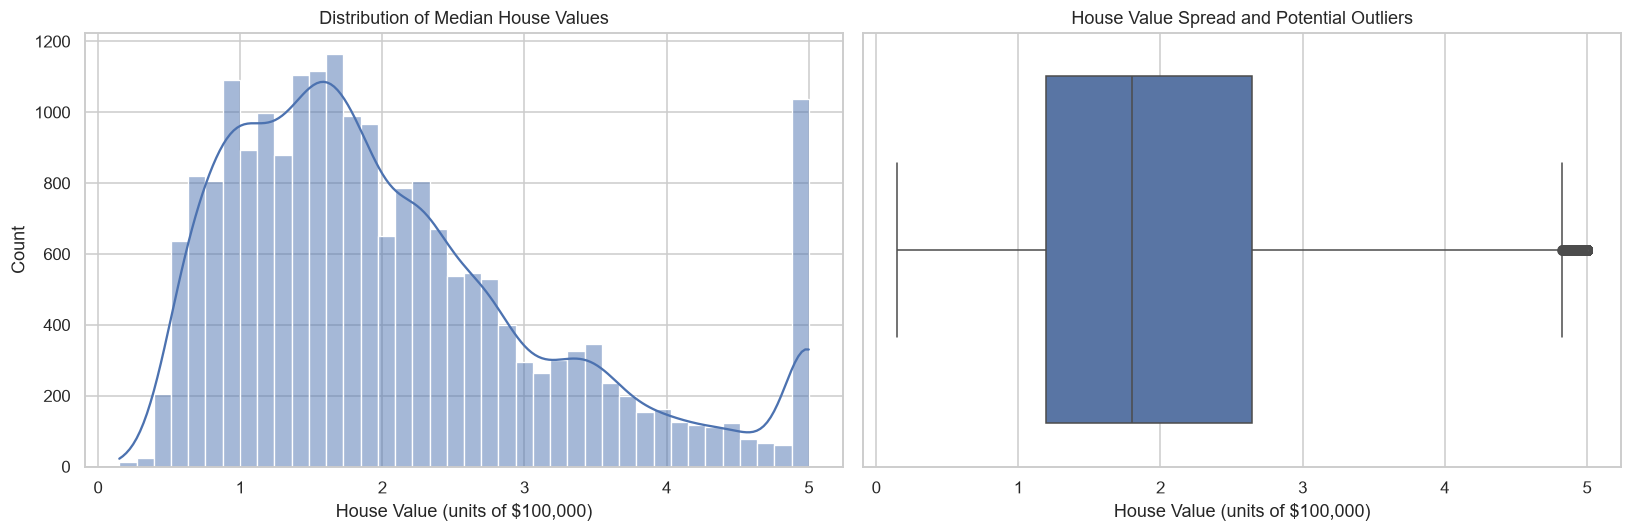

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df,
    x="MedianHouseValue",
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Median House Values")
axes[0].set_xlabel("House Value (units of $100,000)")

sns.boxplot(
    data=df,
    x="MedianHouseValue",
    ax=axes[1]
)
axes[1].set_title("House Value Spread and Potential Outliers")
axes[1].set_xlabel("House Value (units of $100,000)")

plt.tight_layout()
plt.show()

In [8]:
# Step 6: Create meaningful housing features

df_model = df.copy()

df_model["RoomsPerHousehold"] = (
    df_model["AveRooms"] / df_model["AveOccup"]
)

df_model["BedroomsPerRoom"] = (
    df_model["AveBedrms"] / df_model["AveRooms"]
)

df_model["PopulationPerHousehold"] = (
    df_model["Population"] / df_model["AveOccup"]
)

# Replace any infinite values that might arise from division
df_model.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Feature engineering completed.")
print("Dataset shape:", df_model.shape)

display(df_model.head())

Feature engineering completed.
Dataset shape: (20640, 12)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue,RoomsPerHousehold,BedroomsPerRoom,PopulationPerHousehold
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,2.732919,0.146591,126.0
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,2.956685,0.155797,1138.0
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,2.957661,0.129516,177.0
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,2.283154,0.184458,219.0
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,2.879646,0.172096,259.0


## 6. Correlation Analysis

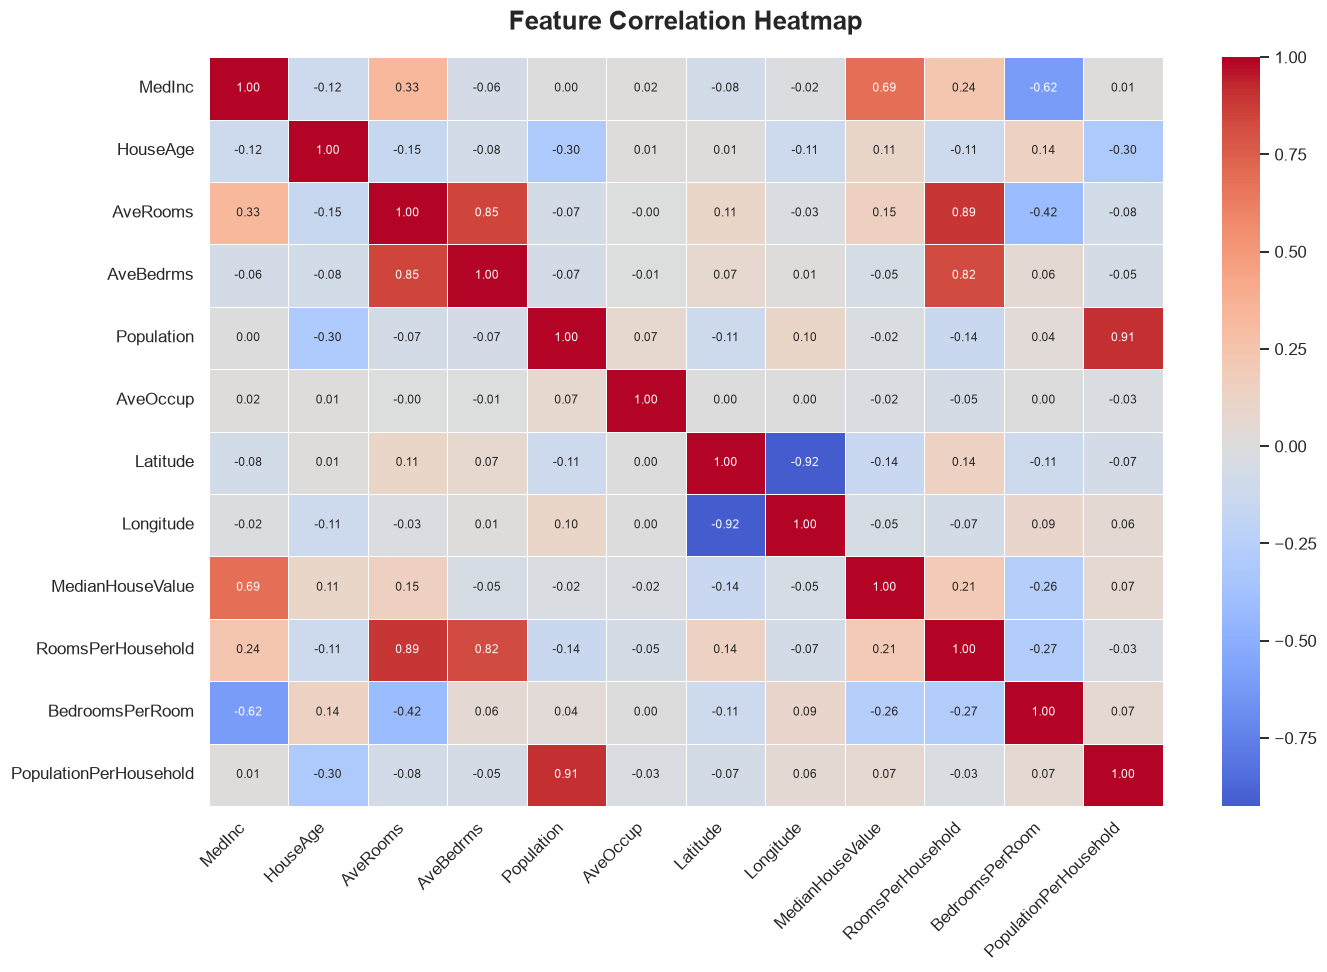

,Correlation with House Value
MedInc,0.688
BedroomsPerRoom,-0.256
RoomsPerHousehold,0.209
AveRooms,0.152
Latitude,-0.144
HouseAge,0.106
PopulationPerHousehold,0.066
AveBedrms,-0.047
Longitude,-0.046
Population,-0.025


In [9]:
# Step 7: Correlation analysis

correlation_matrix = df_model.corr(numeric_only=True)

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title(
    "Feature Correlation Heatmap",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Display the strongest correlations with the target
target_correlations = (
    correlation_matrix["MedianHouseValue"]
    .drop("MedianHouseValue")
    .sort_values(key=abs, ascending=False)
)

display(
    target_correlations.to_frame("Correlation with House Value")
    .round(3)
)

## 7. Train-Test Split and Preprocessing

In [10]:
# Separate features and target
X = df_model.drop(columns=["MedianHouseValue"])
y = df_model["MedianHouseValue"]

# Hold out 20% for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Number of features:", X_train.shape[1])

Training observations: 16512
Testing observations: 4128
Number of features: 11


In [11]:
# Preprocessing: fit imputation and scaling on training data only
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 8. Model Training and Hyperparameter Tuning

In [12]:
# Step 9A: Baseline regression models

models = {
    "OLS (Linear Regression)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=1.0, max_iter=20000)
}

baseline_results = []
baseline_fitted = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    baseline_fitted[name] = pipeline

    baseline_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df.round(4))

,Model,RMSE,MAE,R2
0,OLS (Linear Regression),0.6738,0.4874,0.6535
1,Ridge Regression,0.6738,0.4874,0.6535
2,Lasso Regression,1.1449,0.9061,-0.0002


In [13]:
# Step 9B: Cross-validated hyperparameter tuning

alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

ridge_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Ridge())
])

lasso_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Lasso(max_iter=20000))
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Ridge CV RMSE:", round(-ridge_search.best_score_, 4))

print("\nBest Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best Lasso CV RMSE:", round(-lasso_search.best_score_, 4))

Best Ridge alpha: 10.0
Best Ridge CV RMSE: 0.6744

Best Lasso alpha: 0.001
Best Lasso CV RMSE: 0.6743


In [14]:
# Step 10: Evaluate final models on the held-out test set

final_models = {
    "OLS (Linear Regression)": baseline_fitted["OLS (Linear Regression)"],
    "Ridge (Tuned)": ridge_search.best_estimator_,
    "Lasso (Tuned)": lasso_search.best_estimator_
}

results = []
predictions_dict = {}

for name, model in final_models.items():
    predictions = model.predict(X_test)
    predictions_dict[name] = predictions

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df.round(4))

print("Best model by test RMSE:", results_df.loc[0, "Model"])

,Model,RMSE,MAE,R2
0,OLS (Linear Regression),0.6738,0.4874,0.6535
1,Ridge (Tuned),0.6739,0.4874,0.6535
2,Lasso (Tuned),0.6740,0.4874,0.6533


Best model by test RMSE: OLS (Linear Regression)


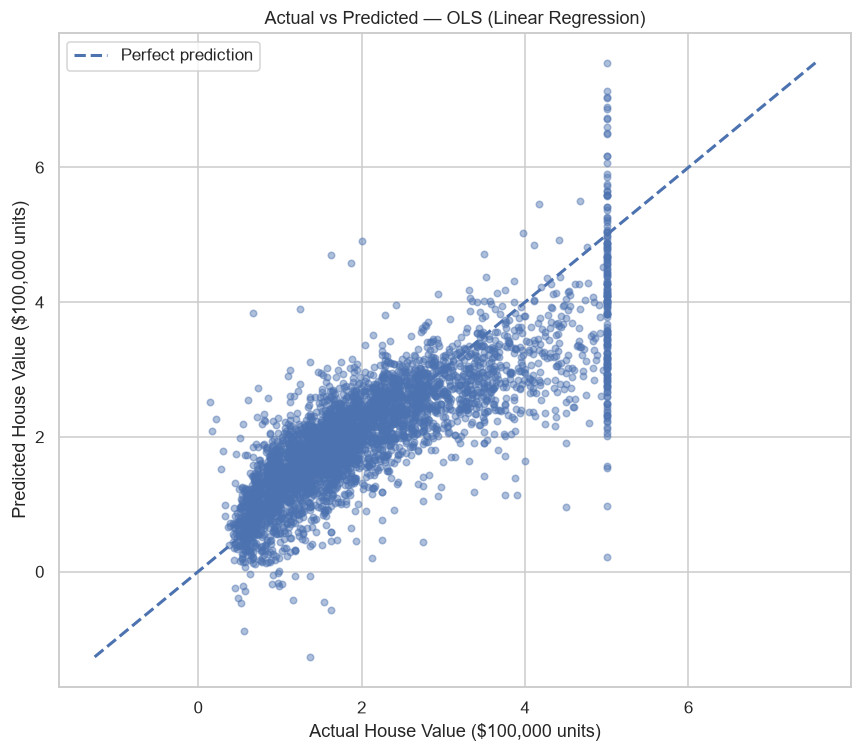

In [15]:
best_model_name = results_df.loc[0, "Model"]
best_predictions = predictions_dict[best_model_name]

plt.figure(figsize=(8, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.45,
    s=18
)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual House Value ($100,000 units)")
plt.ylabel("Predicted House Value ($100,000 units)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

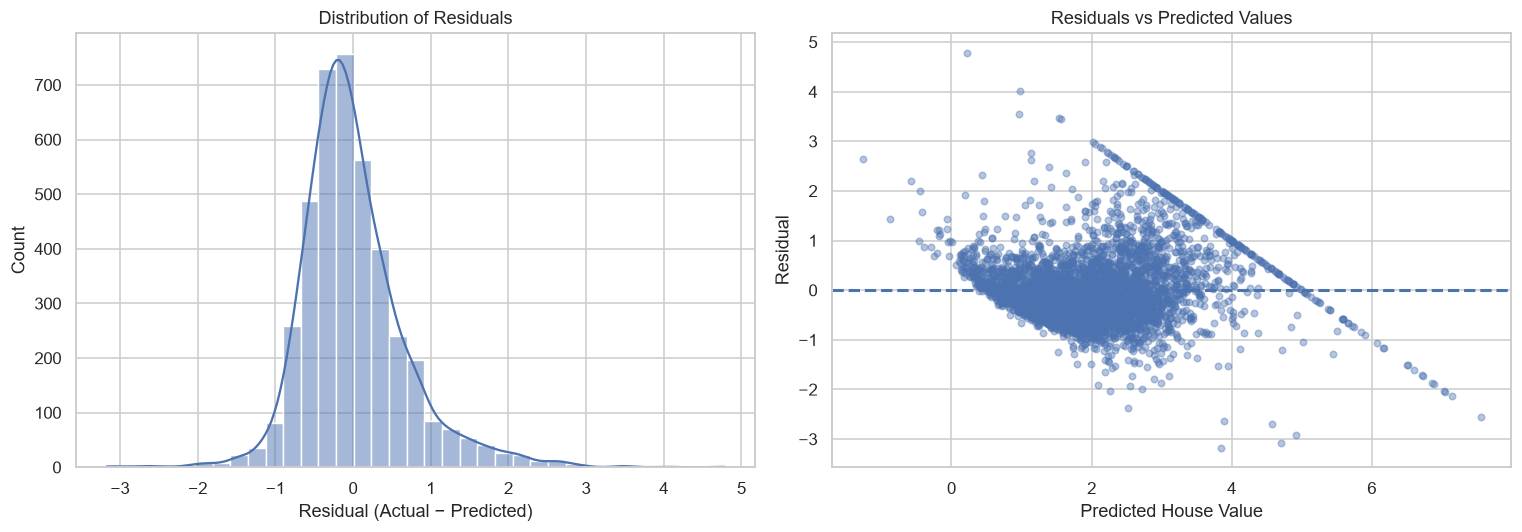

In [16]:
residuals = y_test.to_numpy() - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, bins=35, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residual (Actual − Predicted)")

axes[1].scatter(best_predictions, residuals, alpha=0.4, s=18)
axes[1].axhline(0, linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted House Value")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [17]:
# Step 12: Automated results summary

best_row = results_df.iloc[0]

print("=" * 65)
print("FINAL PROJECT SUMMARY")
print("=" * 65)

print(f"\nBest model by test RMSE: {best_row['Model']}")
print(f"Test RMSE: {best_row['RMSE']:.4f}")
print(f"Test MAE:  {best_row['MAE']:.4f}")
print(f"Test R²:   {best_row['R2']:.4f}")

print("\nMODEL COMPARISON")
display(results_df.round(4))

print("\nCONCLUSION")
print(
    f"The best model by test RMSE was {best_row['Model']}. "
    f"It achieved a test RMSE of {best_row['RMSE']:.4f}, "
    f"an MAE of {best_row['MAE']:.4f}, and an R² of "
    f"{best_row['R2']:.4f}. These results summarize its predictive "
    "performance on the held-out test set. Ridge and Lasso were "
    "also tuned using five-fold cross-validation on the training set."
)

FINAL PROJECT SUMMARY

Best model by test RMSE: OLS (Linear Regression)
Test RMSE: 0.6738
Test MAE:  0.4874
Test R²:   0.6535

MODEL COMPARISON


,Model,RMSE,MAE,R2
0,OLS (Linear Regression),0.6738,0.4874,0.6535
1,Ridge (Tuned),0.6739,0.4874,0.6535
2,Lasso (Tuned),0.6740,0.4874,0.6533



CONCLUSION
The best model by test RMSE was OLS (Linear Regression). It achieved a test RMSE of 0.6738, an MAE of 0.4874, and an R² of 0.6535. These results summarize its predictive performance on the held-out test set. Ridge and Lasso were also tuned using five-fold cross-validation on the training set.
